In [29]:
import pandas as pd
import os
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import RobustScaler
import matplotlib.pyplot as plt

In [47]:
RAIZ = Path("../../")
RUTA_DATOS = RAIZ / "data" / "hu4_esquizofrenia_limpio.csv"
RUTA_DATOS_ORIGINAL = RAIZ / "data" / "hu4_esquizofrenia_limpio_sin_escalar.csv"
RUTA_SALIDA = RAIZ / "data" / "hu5_clusters.csv"

# Con tld_unknown y sin tld_unknown

In [48]:
df = pd.read_csv(RUTA_DATOS)

DROP_COLUMNS = ['nregistro']
DROP_COLUMNS_TLD = ['tld_unknown', 'nregistro']
COLUMNS = COLUMNS = df.drop(columns=DROP_COLUMNS_TLD).columns

df_sin_nregistro = df.drop(columns=DROP_COLUMNS)

df_sin_TLD = df.drop(columns=DROP_COLUMNS_TLD)

# Prueba con kmeans
Vamos a probar con clusters de 2 a 12. Primero con ``df_sin_nregistro`` y después con ``df_sin_TLD``.

Como métricas de decisión, utilizamos:

- **La silueta:** mide el grado en el que cada punto del cluster está cerca de su cluster y lejos del cluster vecino.
- **La inercia:** suma de las distancias al cuadrado de cada punto al centroide. Siempre baja al añadir clusters,
        por eso nos fijamos en el codo, que es el punto en donde la inercia pasa de bajar rápidamente a bajar más despacio.

In [49]:

resultados = {}
print("\nKmeans sin nregistro:")
inercias, siluetas = [], []
for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=10)
    etiquetas = km.fit_predict(df_sin_nregistro)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(df_sin_nregistro, etiquetas))
    print(k, km.inertia_, silhouette_score(df_sin_nregistro, etiquetas))
resultados["sin nregistro"] = (inercias, siluetas)

print("\nKmeans sin nregistro ni tld_unknown:")
inercias, siluetas = [], []
for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=10)
    etiquetas = km.fit_predict(df_sin_TLD)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(df_sin_TLD, etiquetas))
    print(k, km.inertia_, silhouette_score(df_sin_TLD, etiquetas))
resultados["sin nregistro ni tld_unknown"] = (inercias, siluetas)    



Kmeans sin nregistro:
2 9147.221818180305 0.2554303260858876
3 7832.858087118559 0.23266175432961236
4 6806.15780281027 0.23511110133704102
5 6240.684402468856 0.2530599963048045
6 5881.020829193154 0.19073950176138874
7 5395.019297435112 0.20702001715152096
8 5002.626140355374 0.20405980856104247
9 4745.145371319068 0.17453234895715872
10 4403.340615165967 0.19347703454286208
11 4262.230991176297 0.17652596328958706
12 3969.768073381375 0.19385695273844533

Kmeans sin nregistro ni tld_unknown:
2 8949.5591675779 0.260281799355014
3 7636.547469863519 0.2365647342722233
4 6609.150280637381 0.24092693206710927
5 6171.932936303865 0.1787231845419758
6 5610.062668261335 0.2513492157612617
7 5192.526040633618 0.21158901592100612
8 4901.293905938199 0.17676611535333295
9 4560.544081137406 0.17964248757640405
10 4239.324693540369 0.18448197592172402
11 3969.3910854173555 0.19755831971333052
12 3849.7914020509506 0.19029865061722429


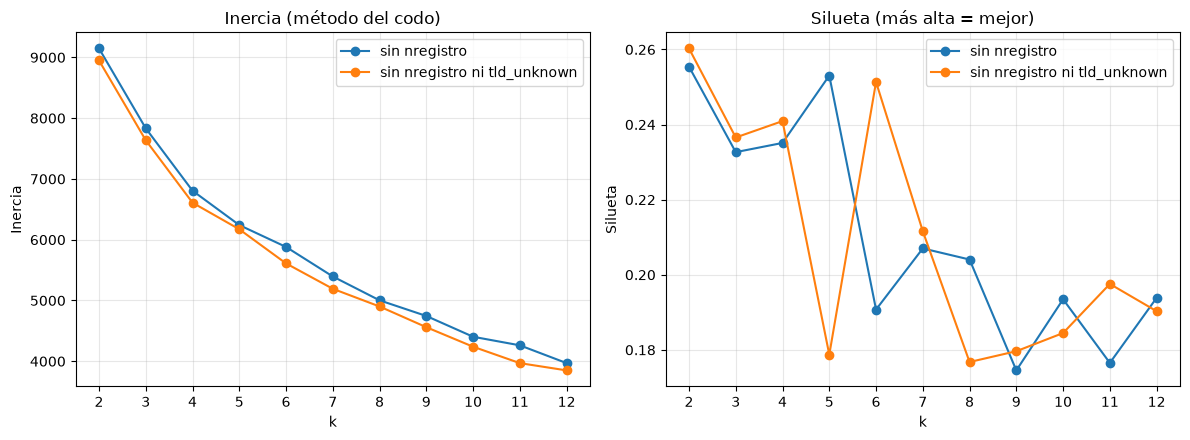

In [50]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ks = list(range(2, 13))
for nombre, (inercias, siluetas) in resultados.items():
    ax1.plot(ks, inercias, marker="o", label=nombre)
    ax2.plot(ks, siluetas, marker="o", label=nombre)

ax1.set_title("Inercia (método del codo)")
ax1.set_xlabel("k")
ax1.set_ylabel("Inercia")

ax2.set_title("Silueta (más alta = mejor)")
ax2.set_xlabel("k")
ax2.set_ylabel("Silueta")

for ax in (ax1, ax2):
    ax.set_xticks(ks)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [51]:
km = KMeans(n_clusters=5, n_init=10, random_state=42)
etiquetas = km.fit_predict(df_sin_TLD)
 
df[["nregistro"]].assign(cluster=etiquetas).to_csv(RUTA_SALIDA, index=False)

In [60]:
df_raw = pd.read_csv(RUTA_DATOS_ORIGINAL)
df_raw["cluster"] = etiquetas

datos = df_raw.drop(columns=["nregistro", "tld_unknown"])

tabla = datos.groupby("cluster").median(numeric_only=True)
tabla.loc["global"] = datos.drop(columns=["cluster"]).median(numeric_only=True)

tabla["n"] = datos["cluster"].value_counts()
tabla.loc["global", "n"] = len(datos)

tabla.T.round(2)

cluster,0,1,2,3,4,global
comercializado,1.00,1.00,1.00,1.00,0.00,1.00
generico,1.00,1.00,0.00,1.00,1.00,1.00
num_excipientes,2.00,2.00,3.00,2.00,4.00,2.00
palabras_seccion_4_4,1678.00,3097.00,1418.00,1668.00,1523.00,1761.00
num_tablas,2.00,2.00,6.00,7.00,4.00,2.00
num_grave,5.00,18.00,11.00,8.00,9.00,6.00
pvp,47.18,64.82,703.12,28.35,187.29,48.61
antiguedad_anios,14.52,11.57,4.70,8.16,2.44,11.61
revocado,0.00,0.00,0.00,0.00,0.00,0.00
dosis_mg,10.00,200.00,700.00,15.00,100.00,15.00


# Conclusiones
## Inercia
La inercia baja rápidamente hasta 4-5 clústers. A partir del sexto clúster, la inercia desciende de manera más lenta.

## Silueta
La mejor silueta es la de 5 clústers sin ``nregistro`` ni ``tld_unknown``. 

## Decisión
Debido a la inercia y a la silueta, decidimos utilizar 5 clústers.